In [43]:
# импорт библиотек (всех-всех-всех)
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib_venn import venn2
import seaborn as sns
import textwrap
from datetime import datetime
import numpy as np
import re
import gdown

# **Импорт данных**

In [44]:
file_id_train = '1TFSldpZ-QZE6OUOhvI6h6Vm63FP-o3St'
file_id_test = '10NeVRmZjcYUrHog9CEqBCR1FBVT-tPiJ'
filename_train = 'train.csv'
filename_test = 'test.csv'

# скачиваем тренировочный датасет
gdown.download(id=file_id_train, output=filename_train, quiet=False)

# преобразовываем в датафрейм
df = pd.read_csv(filename_train)
df

Downloading...
From: https://drive.google.com/uc?id=1TFSldpZ-QZE6OUOhvI6h6Vm63FP-o3St
To: /content/train.csv
100%|██████████| 130k/130k [00:00<00:00, 3.60MB/s]


,Пол,Дата рождения,Онкологический диагноз,Дата постановки онкологического диагноза / начала первичного лечения,Дата удаления первичного очага,Дата развития МГМ,Активирующие мутации,Дата проведения ОВГМ,Дата операции на ГМ,Число РХ процедур на ГН,Дата 1-ой РХ,Индекс Карновского,Число очагов в ГМ,Суммарный объем очагов,Объем максимального очага,Экстракраниальные метастазы,Лекарственное лечение,Локальный рецидив,Дистантные метастазы,Интракраниальная прогрессия
0,М,04.06.1947,НМРЛ,01.04.2008,NaN,01.05.2009,NaN,нет,NaN,1,10.11.2009,70,1,"6,20","6,20",NaN,Химиотерапия,нет,нет,нет
1,М,13.03.1951,РП,01.12.1992,NaN,01.05.2008,NaN,NaN,01.05.2008,3,21.03.2013,70,1,"0,36","0,36",NaN,Таргетная терапия,10.04.2014,10.04.2014,ЛР+ДМ
2,М,21.06.1957,Меланома,01.02.2008,01.02.2008,01.06.2009,NaN,нет,нет,1,08.10.2009,80,3,"0,42","0,37",есть,Химиотерапия,нет,#REF!,ДМ
3,М,24.02.1959,НМРЛ,01.12.2013,не удален,30.05.2014,NaN,NaN,NaN,1,14.07.2014,60,4,"6,39","5,47",есть,Химиотерапия,нет,нет,нет
4,Ж,19.12.1961,КРР,29.12.2010,29.12.2010,01.09.2013,NaN,NaN,01.09.2013,1,26.02.2015,80,3,"5,50","4,62",есть,Таргетная терапия,нет,нет,нет
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
867,М,31.07.1980,Меланома,01.01.2010,01.01.2010,01.03.2010,NaN,нет,нет,1,01.04.2010,70,12,"9,58","4,20",есть,NaN,нет,нет,нет
868,Ж,31.08.1945,НМРЛ,NaN,NaN,NaN,есть,18.04.2012,нет,1,10.04.2012,80,14,"18,82","7,68",есть,Таргетная терапия,нет,нет,нет
869,Ж,31.08.1953,РП,01.07.2007,01.07.2007,01.12.2008,NaN,нет,нет,1,11.01.2009,70,4,"2,46","1,90",есть,Таргетная терапия,нет,нет,нет
870,Ж,31.12.1946,РМЖ,01.12.2004,NaN,01.11.2006,нет,01.12.2006,01.12.2006,1,08.02.2008,80,8,"9,69","4,80",есть,Химиотерапия,нет,нет,нет


In [45]:
# Загружаем тестовый датасет
gdown.download(id=file_id_test, output=filename_test, quiet=False)
test_df = pd.read_csv(filename_test)
display(test_df.head())

Downloading...
From: https://drive.google.com/uc?id=10NeVRmZjcYUrHog9CEqBCR1FBVT-tPiJ
To: /content/test.csv
100%|██████████| 7.15k/7.15k [00:00<00:00, 23.8MB/s]


,ID,Пол,Дата рождения,Онкологический диагноз,Дата постановки онкологического диагноза / начала первичного лечения,Дата удаления первичного очага,Дата развития МГМ,Активирующие мутации,Дата проведения ОВГМ,Дата операции на ГМ,Число РХ процедур на ГН,Дата 1-ой РХ,Индекс Карновского,Число очагов в ГМ,Суммарный объем очагов,Объем максимального очага,Экстракраниальные метастазы,Лекарственное лечение
0,1,Ж,28.05.1924,НМРЛ,01.06.2011,не удален,01.07.2011,NaN,нет,нет,2,26.09.2011,70,8,"11,57","7,1",NaN,Химиотерапия
1,2,М,12.03.1930,Меланома,01.01.2009,01.01.2009,01.01.2010,NaN,нет,нет,2,01.03.2010,80,2,"4,6","2,7",NaN,Без лечения
2,3,Ж,08.10.1934,Меланома,01.02.2010,01.02.2010,01.10.2010,NaN,нет,нет,1,10.11.2010,80,1,"4,4","4,4",NaN,Химиотерапия
3,4,Ж,25.04.1936,РМЖ,01.12.2004,NaN,05.07.2013,нет,нет,нет,1,18.07.2013,60,7,"8,72","7,26",есть,Химиотерапия
4,5,Ж,21.06.1938,РП,01.08.2007,не удален,13.08.2008,NaN,нет,нет,1,29.09.2008,70,2,"5,6",4,есть,Химиотерапия


# **Data preparation**

## Обработка дат течения болезни

In [46]:
# нормализируем даты (object -> datetime)
datetime_columns = ['Дата 1-ой РХ', 'Дата рождения',
                 'Дата постановки онкологического диагноза / начала первичного лечения',
                 'Дата развития МГМ']

# перебираем все признаки, описывающие дату
for col_name in datetime_columns:
    for i in range(len(test_df[col_name])):
        # на всякий случай заменяем разделители
        clean_str = str(test_df.loc[i, col_name]).replace('-', '.').replace('/', '.')
        # удаляем все, что не является цифрой и точкой (спец символы)
        test_df.loc[i, col_name] = re.sub(r'[^\d.]', '', clean_str)

# преобразовываем данные в естественный вид по формату %d.%m.%Y
for col_name in datetime_columns:
    test_df[col_name] = pd.to_datetime(test_df[col_name], errors='coerce', format="%d.%m.%Y")
test_df.dtypes

,0
ID,int64
Пол,object
Дата рождения,datetime64[ns]
Онкологический диагноз,object
Дата постановки онкологического диагноза / начала первичного лечения,datetime64[ns]
Дата удаления первичного очага,object
Дата развития МГМ,datetime64[ns]
Активирующие мутации,object
Дата проведения ОВГМ,object
Дата операции на ГМ,object


In [47]:
# нормализируем даты (object -> datetime)
datetime_columns = ['Дата 1-ой РХ', 'Дата рождения',
                 'Дата постановки онкологического диагноза / начала первичного лечения',
                 'Дата развития МГМ']

# перебираем все признаки, описывающие дату
for col_name in datetime_columns:
    for i in range(len(df[col_name])):
        # на всякий случай заменяем разделители
        clean_str = str(df.loc[i, col_name]).replace('-', '.').replace('/', '.')
        # удаляем все, что не является цифрой и точкой (спец символы)
        df.loc[i, col_name] = re.sub(r'[^\d.]', '', clean_str)

# преобразовываем данные в естественный вид по формату %d.%m.%Y
for col_name in datetime_columns:
    df[col_name] = pd.to_datetime(df[col_name], errors='coerce', format="%d.%m.%Y")
df.dtypes

,0
Пол,object
Дата рождения,datetime64[ns]
Онкологический диагноз,object
Дата постановки онкологического диагноза / начала первичного лечения,datetime64[ns]
Дата удаления первичного очага,object
Дата развития МГМ,datetime64[ns]
Активирующие мутации,object
Дата проведения ОВГМ,object
Дата операции на ГМ,object
Число РХ процедур на ГН,int64


In [48]:
# создаём интерпретируемые признаки для дат

# ВОЗРАСТ = ВОЗРАСТ НА МОМЕНТ ПЕРВОЙ ОПЕРАЦИИ НА ГАММА НОЖЕ
df["Возраст"] = ((df["Дата 1-ой РХ"] - df["Дата рождения"]).dt.days / 365.25).round()

# ВРЕМЯ РЕАГИРОВАНИЯ = КОЛ-ВО ДНЕЙ МЕЖДУ РАЗВИТИЕМ МГМ И ОПЕРАЦИИ НА ГАММА НОЖЕ
df["Время реагирования"] = (df["Дата 1-ой РХ"] - df["Дата развития МГМ"]).dt.days

# ВРЕМЯ МЕТАСТАЗИРОВАНИЯ = КОЛ-ВО ДНЕМ МЕЖДУ РАЗВИТИЕМ МГМ И ОБНАРУЖЕНИЕМ ОНКОЛОГИИ
df["Время метастазирования"] = (df["Дата развития МГМ"] - df["Дата постановки онкологического диагноза / начала первичного лечения"]).dt.days

In [49]:
# СОЗДАЁМ ИНТЕРПРЕТИРУЕМЫЕ ПРИЗНАКИ ДЛЯ ТЕСТОВОГО НАБОРА
test_df["Возраст"] = ((test_df["Дата 1-ой РХ"] - test_df["Дата рождения"]).dt.days / 365.25).round()
test_df["Время реагирования"] = (test_df["Дата 1-ой РХ"] - test_df["Дата развития МГМ"]).dt.days
test_df["Время метастазирования"] = (test_df["Дата развития МГМ"] - test_df["Дата постановки онкологического диагноза / начала первичного лечения"]).dt.days

In [50]:
# рассматриваем значения новых признаков
for col_name in ['Возраст', "Время реагирования", "Время метастазирования"]:
  counts = df[col_name].value_counts().sort_index().head(5)
  display(counts)

,count
Возраст,
23.0,1
25.0,3
26.0,2
28.0,6
29.0,3


,count
Время реагирования,
-3634.0,1
-3625.0,1
-3623.0,1
-2747.0,1
-691.0,1


,count
Время метастазирования,
-76.0,1
-62.0,1
-35.0,1
-30.0,3
-18.0,1


In [51]:
# замечаем отрицательные значения в новых признаках (некорректный ввод дат),
# создаём функцию-обработчик отрицаительных значений
def negative_handler(value):
  if value < 0.0:
    value = 0.0
  return value

# обрабатываем значения:
for col_name in ['Время реагирования']:
  df[col_name] = df[col_name].apply(negative_handler)

# прописываем бинарный признак, отвечающий за факапы со временем
df['Временные аномалии'] = (
    ((df["Дата 1-ой РХ"] - df["Дата развития МГМ"]).dt.days < 0)
).astype(int)

# выводим распределение значений
display(df['Временные аномалии'].value_counts())

# в признаке "Время метастазирования" мы не заменяем отрицательные значения,
# поскольку МГМ могут быть обнаружена до постановки онкологического диагноза

,count
Временные аномалии,
0,864
1,8


In [52]:
# ОБРАБАТЫВАЕМ ЗНАЧЕНИЯ ДЛЯ ТЕСТОВОГО НАБОРА
for col_name in ['Время реагирования']:
  test_df[col_name] = test_df[col_name].apply(negative_handler)

test_df['Временные аномалии'] = (
    ((test_df["Дата 1-ой РХ"] - test_df["Дата развития МГМ"]).dt.days < 0)
).astype(int)

In [53]:
# Обработка аномалий времени для test_df
test_df['Время реагирования'] = test_df['Время реагирования'].apply(negative_handler)
test_df['Временные аномалии'] = ((test_df["Дата 1-ой РХ"] - test_df["Дата развития МГМ"]).dt.days < 0).astype(int)

display(test_df['Временные аномалии'].value_counts())

,count
Временные аномалии,
0,44


## Обработка дат сопустствующих факторов болезни

In [54]:
def map_binary(negative_word):
  def mapping(x):
    if pd.isna(x):
      return np.nan
    elif str(x).strip().lower() == negative_word:
        return 0
    else:
        return 1
  return mapping
# создаём интерпретируемые признаки из вспомогательных дат

# ПЕРВИЧНЫЙ ОЧАГ ДО 1-ОЙ РХ = 1 ЕСЛИ ПЕРВИЧНЫЙ ОЧАГ НЕ УДАЛЁН ДО 1-ОЙ РХ, 0 ЕСЛИ НЕТ, NAN ИНАЧЕ
# ВРЕМЯ ОТ УДАЛЕНИЯ ПЕРВИЧНОГО ОЧАГА ДО 1-ОЙ РХ (0 ЕСЛИ УДАЛЕНО ПОЗЖЕ, NaN ИНАЧЕ)

# создаём бинарный признак наличия вспомогательного лечения:
df["Первичный очаг до 1-ой РХ"] = df['Дата удаления первичного очага'].apply(map_binary('не удален'))
# приводим дату к нужному формату:
df['Дата удаления первичного очага'] = pd.to_datetime(df["Дата удаления первичного очага"], errors='coerce', format="%d.%m.%Y")
# вычисляем расстояние в днях от вспомогательного лечения до 1-ой РХ (может быть отрицательным)
df['Время от удаления первичного очага до 1-ой РХ'] = df['Первичный очаг до 1-ой РХ'] * (df['Дата 1-ой РХ'] - df['Дата удаления первичного очага']).dt.days
# ограничиваем
df['Первичный очаг до 1-ой РХ'] = ((df["Первичный очаг до 1-ой РХ"] == 1) & (df['Дата удаления первичного очага'] <= df['Дата 1-ой РХ']))


# ОВГМ ДО ПЕРВОЙ РХ = 1 ЕСЛИ БЫЛА ОВГМ ДО 1-ОЙ РХ, 0 ЕСЛИ НЕТ, NAN ИНАЧЕ
# ВРЕМЯ ОТ ОВГМ ДО 1-ОЙ РХ (0 ЕСЛИ ОВГМ ПОЗЖЕ, NaN ИНАЧЕ)
df['ОВГМ до 1-ой РХ'] = df['Дата проведения ОВГМ'].apply(map_binary('нет'))
df['Дата проведения ОВГМ'] = pd.to_datetime(df["Дата проведения ОВГМ"], errors='coerce', format="%d.%m.%Y")
df['Время от ОВГМ до 1-ой РХ'] = df['ОВГМ до 1-ой РХ'] * (df['Дата 1-ой РХ'] - df['Дата проведения ОВГМ']).dt.days
df['ОВГМ до 1-ой РХ'] = ((df["ОВГМ до 1-ой РХ"] == 1) & (df['Дата проведения ОВГМ'] <= df['Дата 1-ой РХ']))


# ОПЕРАЦИЯ НА ГМ ДО 1-ОЙ РХ = 1 ЕСЛИ БЫЛА ОПЕРАЦИЯ НА ГМ ДО 1-ОЙ РХ, 0 ЕСЛИ НЕТ, NAN ИНАЧЕ
# ВРЕМЯ ОТ ОПЕРАЦИИ НА ГМ ДО 1-ОЙ РХ (0 ЕСЛИ ОПЕРАЦИЯ ПОЗЖЕ, NaN ИНАЧЕ)
df["Операция на ГМ до 1-ой РХ"] = df['Дата операции на ГМ'].apply(map_binary('нет'))
df['Дата операции на ГМ'] = pd.to_datetime(df["Дата операции на ГМ"], errors='coerce', format="%d.%m.%Y")
df["Время от операции на ГМ до 1-ой РХ"] = df['Операция на ГМ до 1-ой РХ'] * (df['Дата 1-ой РХ'] - df['Дата операции на ГМ']).dt.days
df['Операция на ГМ до 1-ой РХ'] = ((df["Операция на ГМ до 1-ой РХ"] == 1) & (df['Дата операции на ГМ'] <= df['Дата 1-ой РХ']))


In [55]:
# ВСПОМОГАТЕЛЬНОЕ ЛЕЧЕНИЕ ДЛЯ ТЕСТОВОГО НАБОРА
test_df["Первичный очаг до 1-ой РХ"] = test_df['Дата удаления первичного очага'].apply(map_binary('не удален'))
test_df['Дата удаления первичного очага'] = pd.to_datetime(test_df["Дата удаления первичного очага"], errors='coerce', format="%d.%m.%Y")
test_df['Время от удаления первичного очага до 1-ой РХ'] = test_df['Первичный очаг до 1-ой РХ'] * (test_df['Дата 1-ой РХ'] - test_df['Дата удаления первичного очага']).dt.days
test_df['Первичный очаг до 1-ой РХ'] = ((test_df["Первичный очаг до 1-ой РХ"] == 1) & (test_df['Дата удаления первичного очага'] <= test_df['Дата 1-ой РХ']))

test_df['ОВГМ до 1-ой РХ'] = test_df['Дата проведения ОВГМ'].apply(map_binary('нет'))
test_df['Дата проведения ОВГМ'] = pd.to_datetime(test_df["Дата проведения ОВГМ"], errors='coerce', format="%d.%m.%Y")
test_df['Время от ОВГМ до 1-ой РХ'] = test_df['ОВГМ до 1-ой РХ'] * (test_df['Дата 1-ой РХ'] - test_df['Дата проведения ОВГМ']).dt.days
test_df['ОВГМ до 1-ой РХ'] = ((test_df["ОВГМ до 1-ой РХ"] == 1) & (test_df['Дата проведения ОВГМ'] <= test_df['Дата 1-ой РХ']))

test_df["Операция на ГМ до 1-ой РХ"] = test_df['Дата операции на ГМ'].apply(map_binary('нет'))
test_df['Дата операции на ГМ'] = pd.to_datetime(test_df["Дата операции на ГМ"], errors='coerce', format="%d.%m.%Y")
test_df["Время от операции на ГМ до 1-ой РХ"] = test_df['Операция на ГМ до 1-ой РХ'] * (test_df['Дата 1-ой РХ'] - test_df['Дата операции на ГМ']).dt.days
test_df['Операция на ГМ до 1-ой РХ'] = ((test_df["Операция на ГМ до 1-ой РХ"] == 1) & (test_df['Дата операции на ГМ'] <= test_df['Дата 1-ой РХ']))

## Обработка числовых данных

In [56]:
# преобразовываем числовые признаки в корректный формат (object -> int/float)
df['Суммарный объем очагов'] = pd.to_numeric(df['Суммарный объем очагов'].str.replace(',', '.'))

df['Объем максимального очага'] = pd.to_numeric(df['Объем максимального очага'].str.replace(',', '.'))

df['Активирующие мутации'] = df['Активирующие мутации'].map({"есть": 1, "нет": 0})

df['Число очагов в ГМ'] = pd.to_numeric(df['Число очагов в ГМ'])

In [57]:
# ЧИСЛОВЫЕ ПРИЗНАКИ ДЛЯ ТЕСТОВОГО НАБОРА
test_df['Суммарный объем очагов'] = pd.to_numeric(test_df['Суммарный объем очагов'].astype(str).str.replace(',', '.'), errors='coerce')
test_df['Объем максимального очага'] = pd.to_numeric(test_df['Объем максимального очага'].astype(str).str.replace(',', '.'), errors='coerce')
test_df['Активирующие мутации'] = test_df['Активирующие мутации'].map({"есть": 1, "нет": 0})
test_df['Число очагов в ГМ'] = pd.to_numeric(test_df['Число очагов в ГМ'], errors='coerce')

## Анализ целевой переменной

In [58]:
# проверяем, что при пустом значении прогрессии нет информации
# о локальных рецидивах и дистантных метастазах
display(df[df['Интракраниальная прогрессия'].isna()]['Локальный рецидив'].unique())
display(df[df['Интракраниальная прогрессия'].isna()]['Дистантные метастазы'].unique())

# удалим значения с пропущенным значением целевой переменной
df = df.dropna(subset=["Интракраниальная прогрессия"]).copy()

array([nan], dtype=object)

array([nan], dtype=object)

In [59]:
# выведем все виды значений в "Интракраниальная прогрессия"
display(df["Интракраниальная прогрессия"].value_counts())

# определяем ожидаемые значения для столбца "Интракраниальная прогрессия"
def determine_expected_ip(local, distant):
    # проверяем, есть ли локальный рецидив
    has_local = isinstance(local, str) and local != "нет"
    # проверяем, есть ли дистантные метастазы
    has_distant = isinstance(distant, str) and distant != "нет"

    if has_local and has_distant:
        return "ЛР+ДМ"
    elif has_local:
        return "ЛР"
    elif has_distant:
        return "ДМ"
    else:
        return "нет"

# применяем функцию к каждой строке DataFrame для определения ожидаемого значения
df["Ожидаемая прогрессия"] = df.apply(
    lambda row: determine_expected_ip(row["Локальный рецидив"], row["Дистантные метастазы"]),
    axis=1
)

# выводим ошибки
errors = df[df["Интракраниальная прогрессия"] != df["Ожидаемая прогрессия"]]
if not errors.empty:
    print("\nНайдены ошибки в столбце 'Интракраниальная прогрессия':")
    display(errors[["Локальный рецидив", "Дистантные метастазы", "Интракраниальная прогрессия", "Ожидаемая прогрессия"]])
else:
    print("\nВсе значения в 'Интракраниальная прогрессия' заполнены правильно.")

,count
Интракраниальная прогрессия,
ДМ,279
нет,235
ЛР+ДМ,99
ЛР,67



Найдены ошибки в столбце 'Интракраниальная прогрессия':


,Локальный рецидив,Дистантные метастазы,Интракраниальная прогрессия,Ожидаемая прогрессия
24,23.11.2009,23.11.2009,ЛР,ЛР+ДМ
51,нет,09.05.2009,нет,ДМ
97,25.07.2013,25.07.2013,ЛР,ЛР+ДМ
104,22.10.2012,нет,нет,ЛР
111,нет,20.12.2016,нет,ДМ
241,15.07.2014,03.04.2013,ДМ,ЛР+ДМ
292,17.07.2017,нет,нет,ЛР
301,#REF!,31.08.2015,ДМ,ЛР+ДМ
361,нет,05.06.2017,нет,ДМ
385,нет,11.10.2017,нет,ДМ


In [60]:
# правим ошибки подсчёта (REF)
display(df.loc[301, ["Локальный рецидив", "Дистантные метастазы", "Интракраниальная прогрессия", "Ожидаемая прогрессия"]])
df.loc[301, 'Ожидаемая прогрессия'] = 'ДМ'
display(df.loc[301, ["Локальный рецидив", "Дистантные метастазы", "Интракраниальная прогрессия", "Ожидаемая прогрессия"]])

,301
Локальный рецидив,#REF!
Дистантные метастазы,31.08.2015
Интракраниальная прогрессия,ДМ
Ожидаемая прогрессия,ЛР+ДМ


,301
Локальный рецидив,#REF!
Дистантные метастазы,31.08.2015
Интракраниальная прогрессия,ДМ
Ожидаемая прогрессия,ДМ


In [61]:
# за ненадобностью удаляем предыдущий таргет
df = df.drop("Интракраниальная прогрессия", axis=1)

## Анализ признака "Пол"

In [62]:
# анализируем значения пола
print("До:")
gender_counts = df['Пол'].value_counts()
display(gender_counts)

# приводим все значения к одному регистру
df['Пол'] = df['Пол'].str.upper()

# ПОЛ-МУЖСКОЙ = БИНАРНЫЙ ПРИЗНАК, ОБОЗНАЧАЮЩИЙ ПРИНАДЛЕЖНОСТЬ К МУЖСКОМУ ПОЛУ
df['Пол-Мужской'] = df['Пол'].replace({'М' : '0', 'Ж' : '1'}).astype(int)

# удаляем неинформативный признак
df = df.drop("Пол", axis=1)

# выводим уникальные значения
print("После:")
gender_counts = df['Пол-Мужской'].value_counts()
display(gender_counts)

До:


,count
Пол,
Ж,393
М,266
ж,14
м,7


После:


,count
Пол-Мужской,
1,407
0,273


In [63]:
# КОДИРОВАНИЕ ПОЛА ДЛЯ ТЕСТОВОГО НАБОРА
test_df['Пол'] = test_df['Пол'].str.upper()
test_df['Пол-Мужской'] = test_df['Пол'].replace({'М' : '0', 'Ж' : '1'}).astype(int)

## Анализ временных признаков

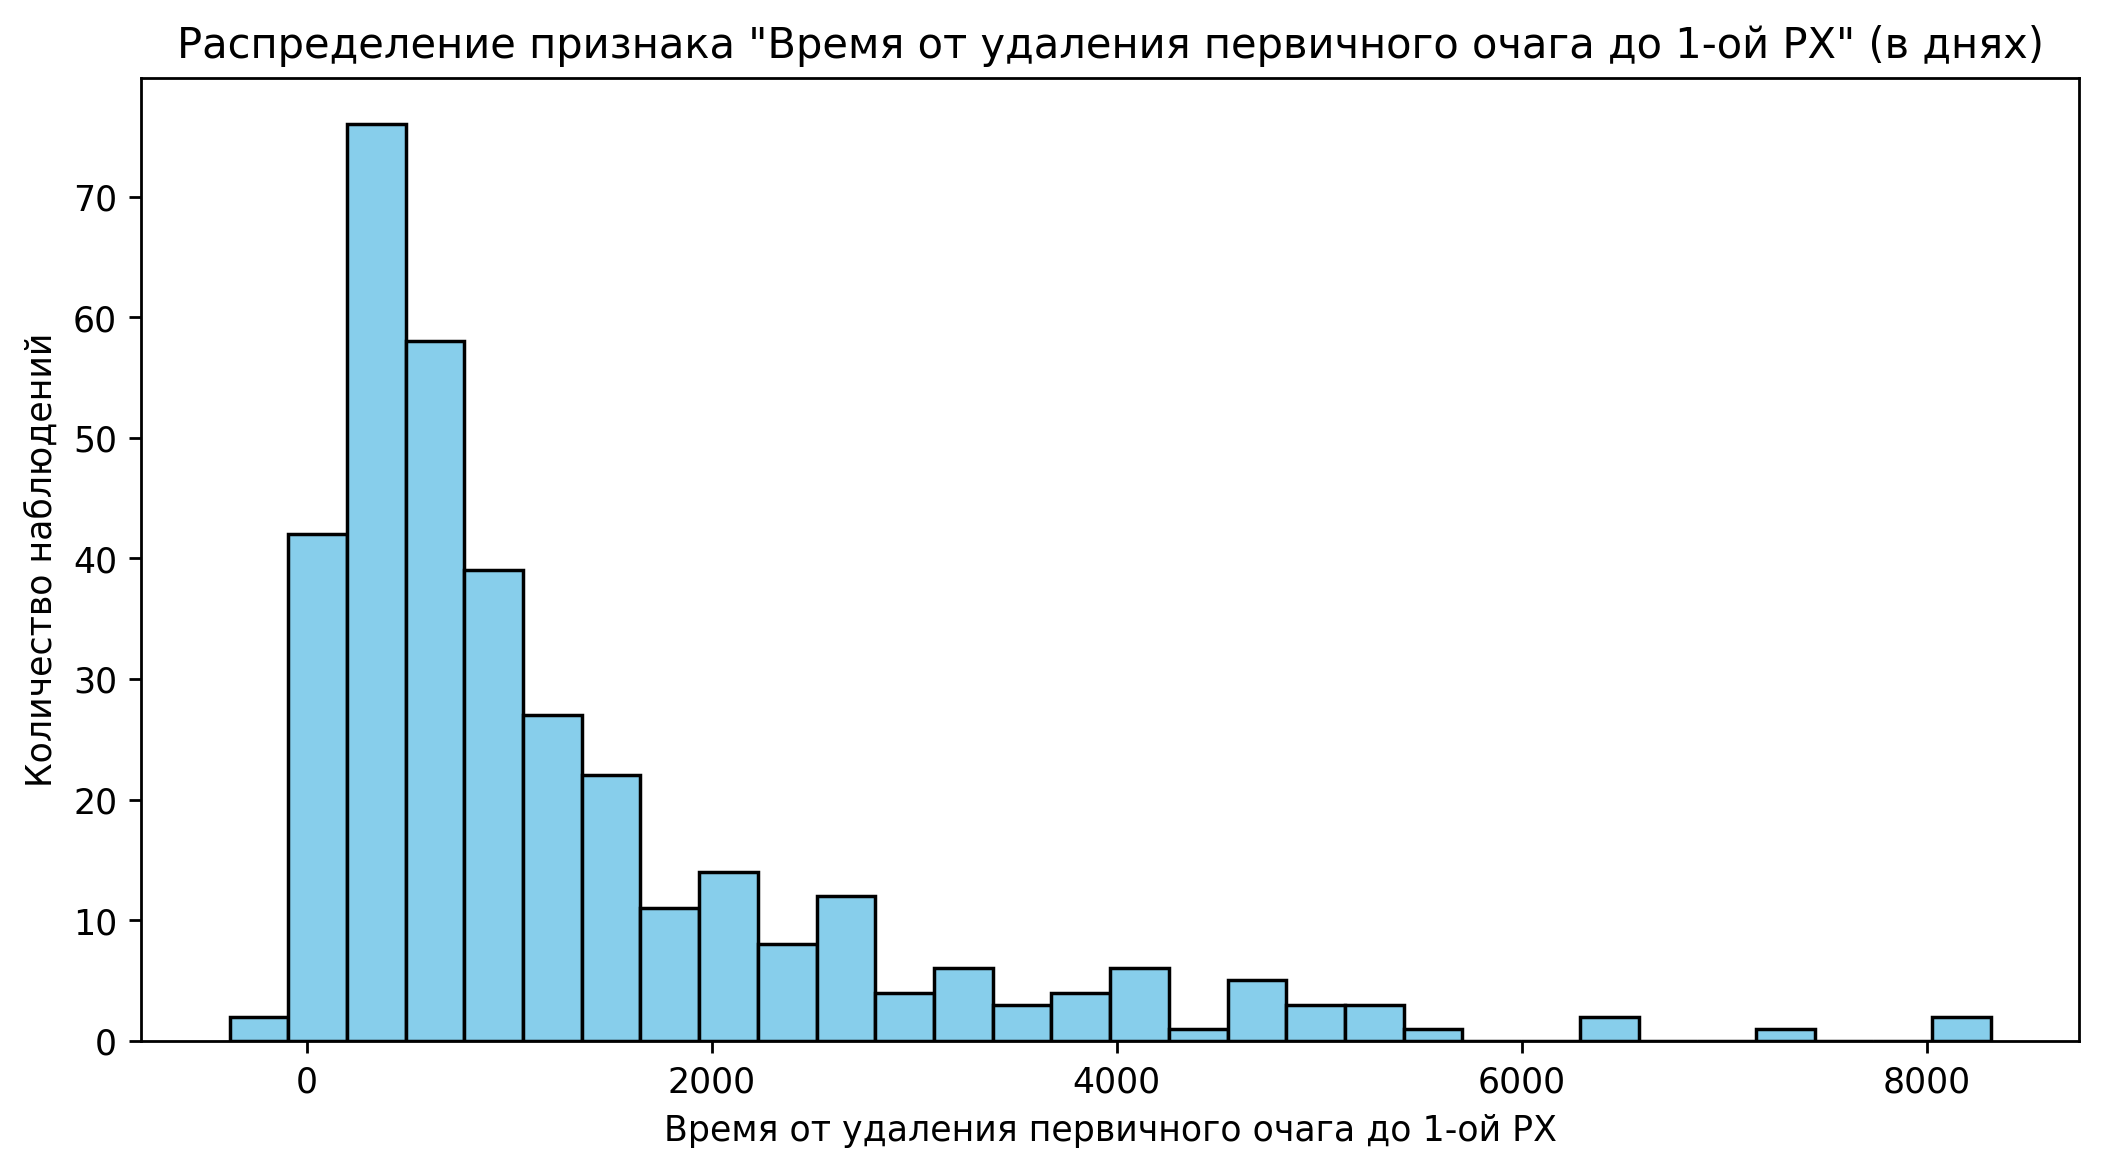

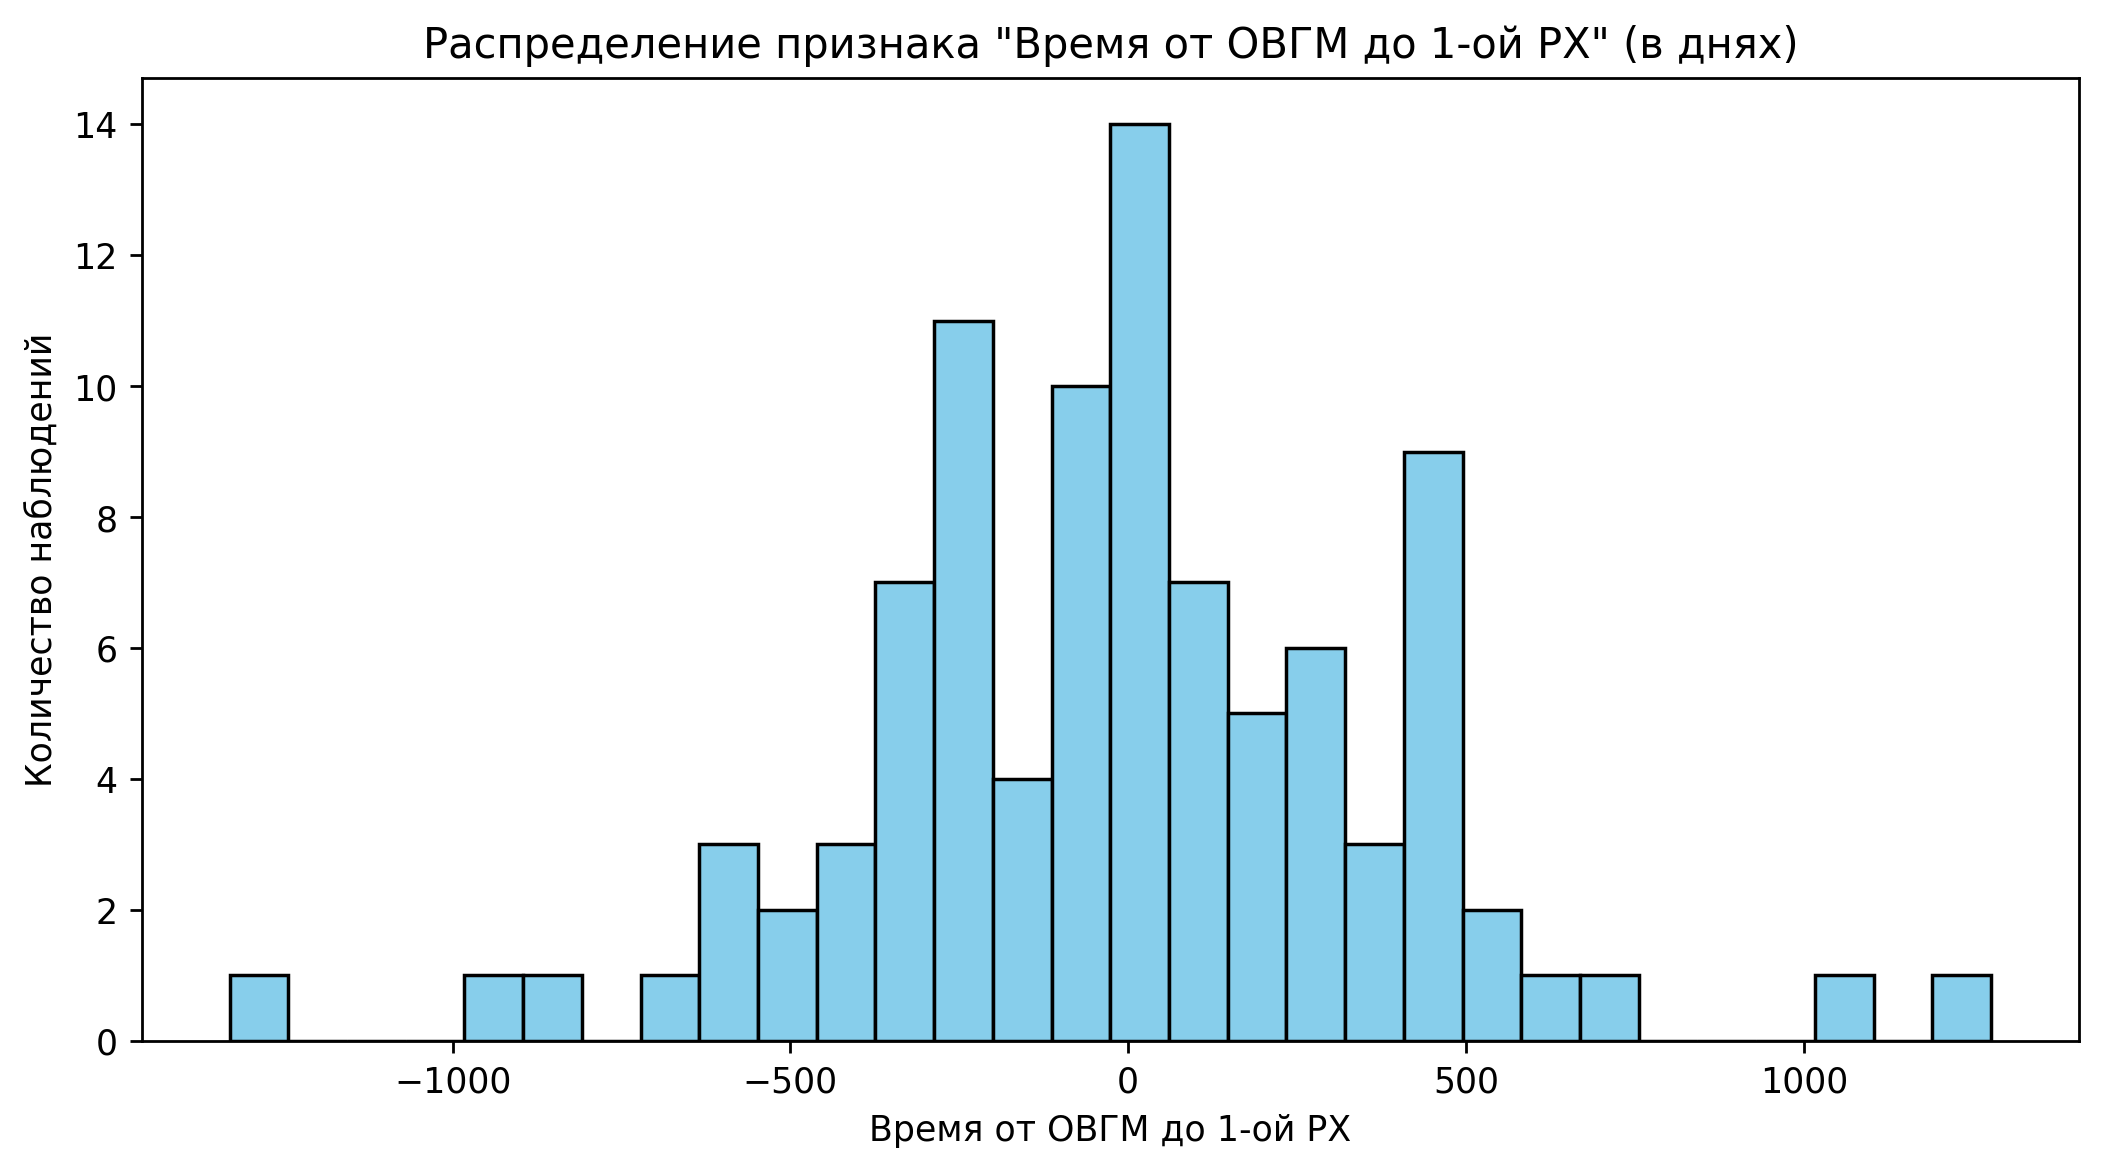

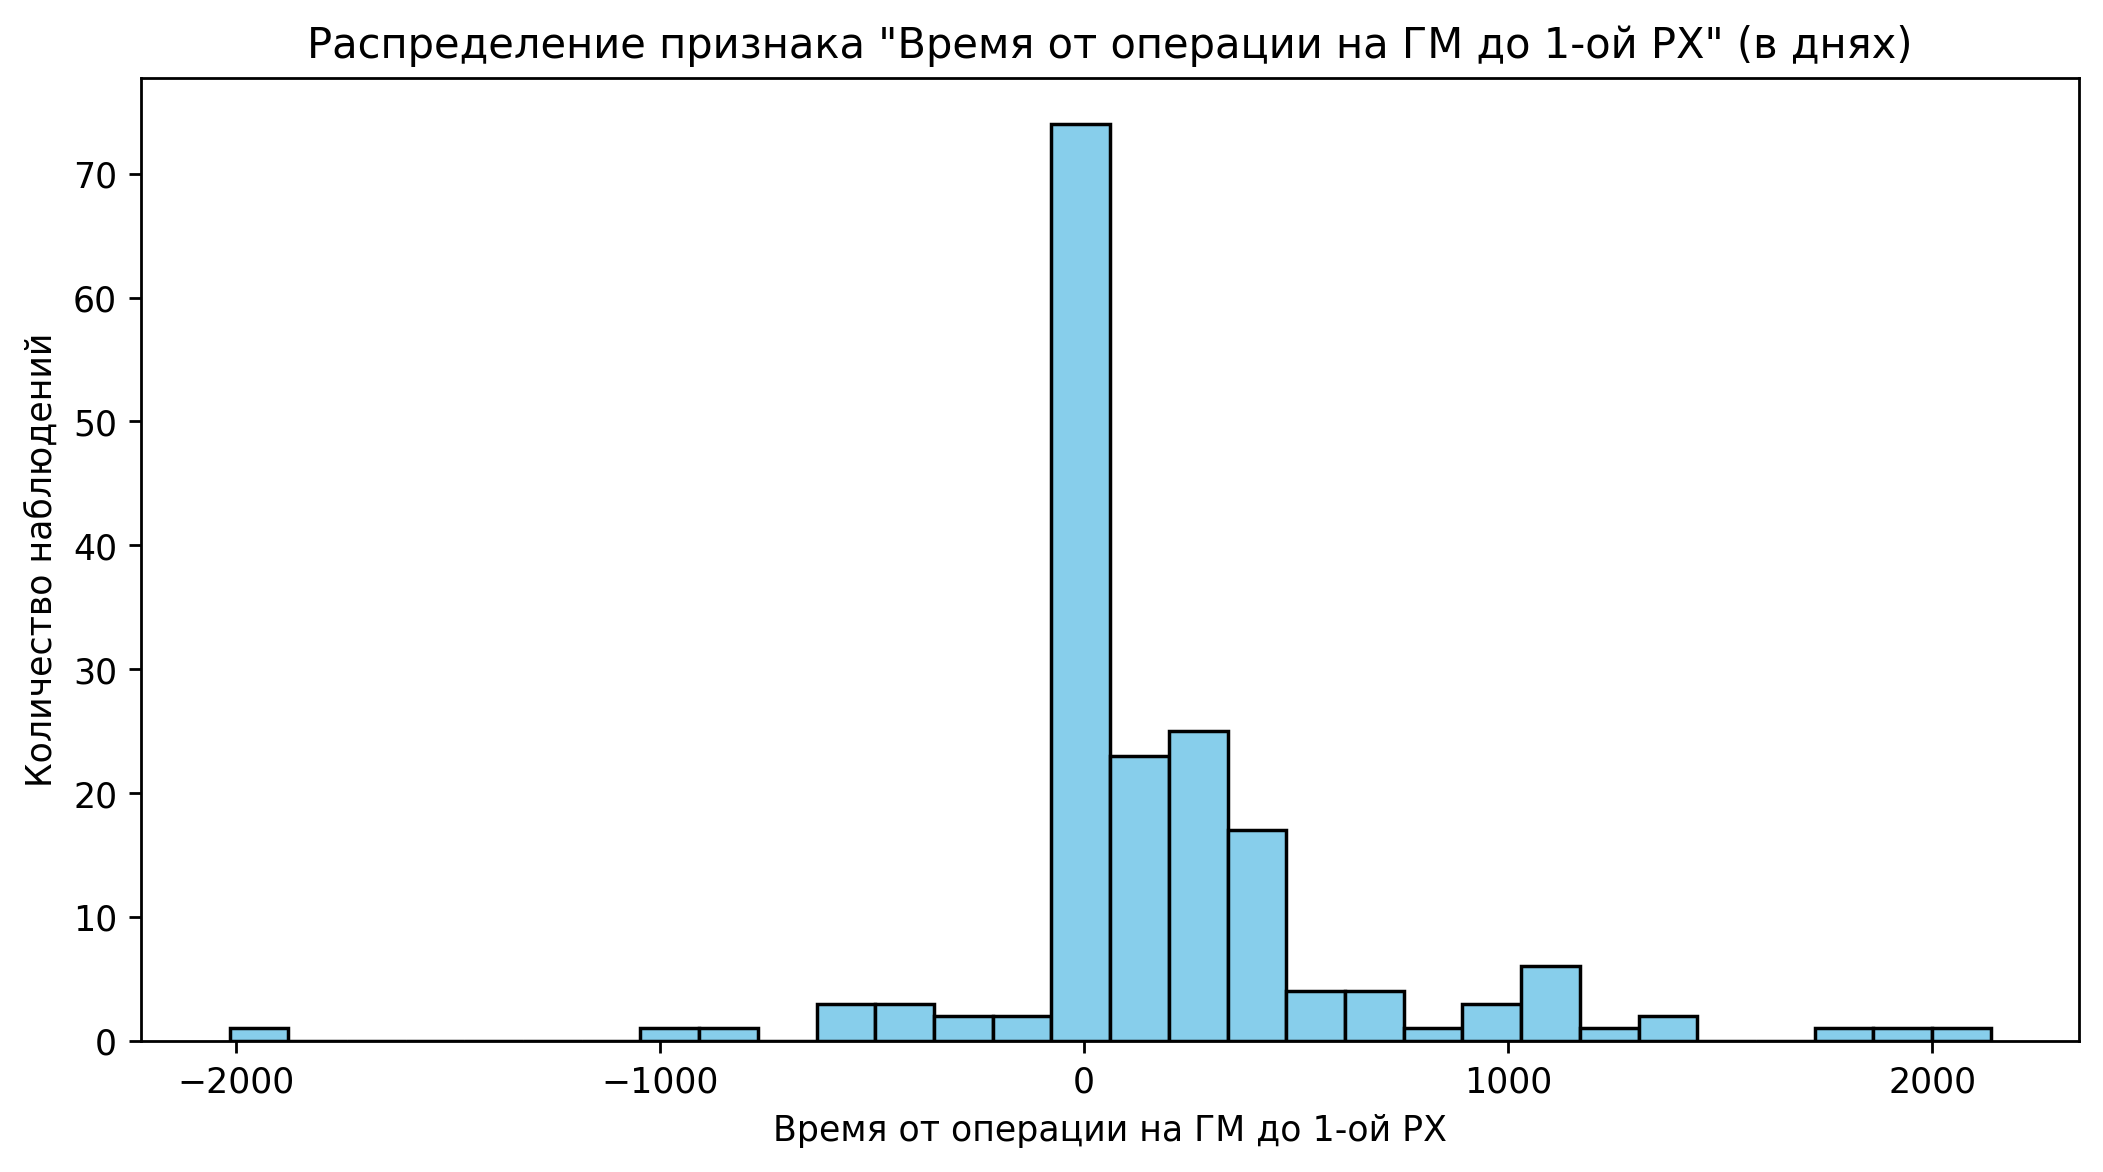

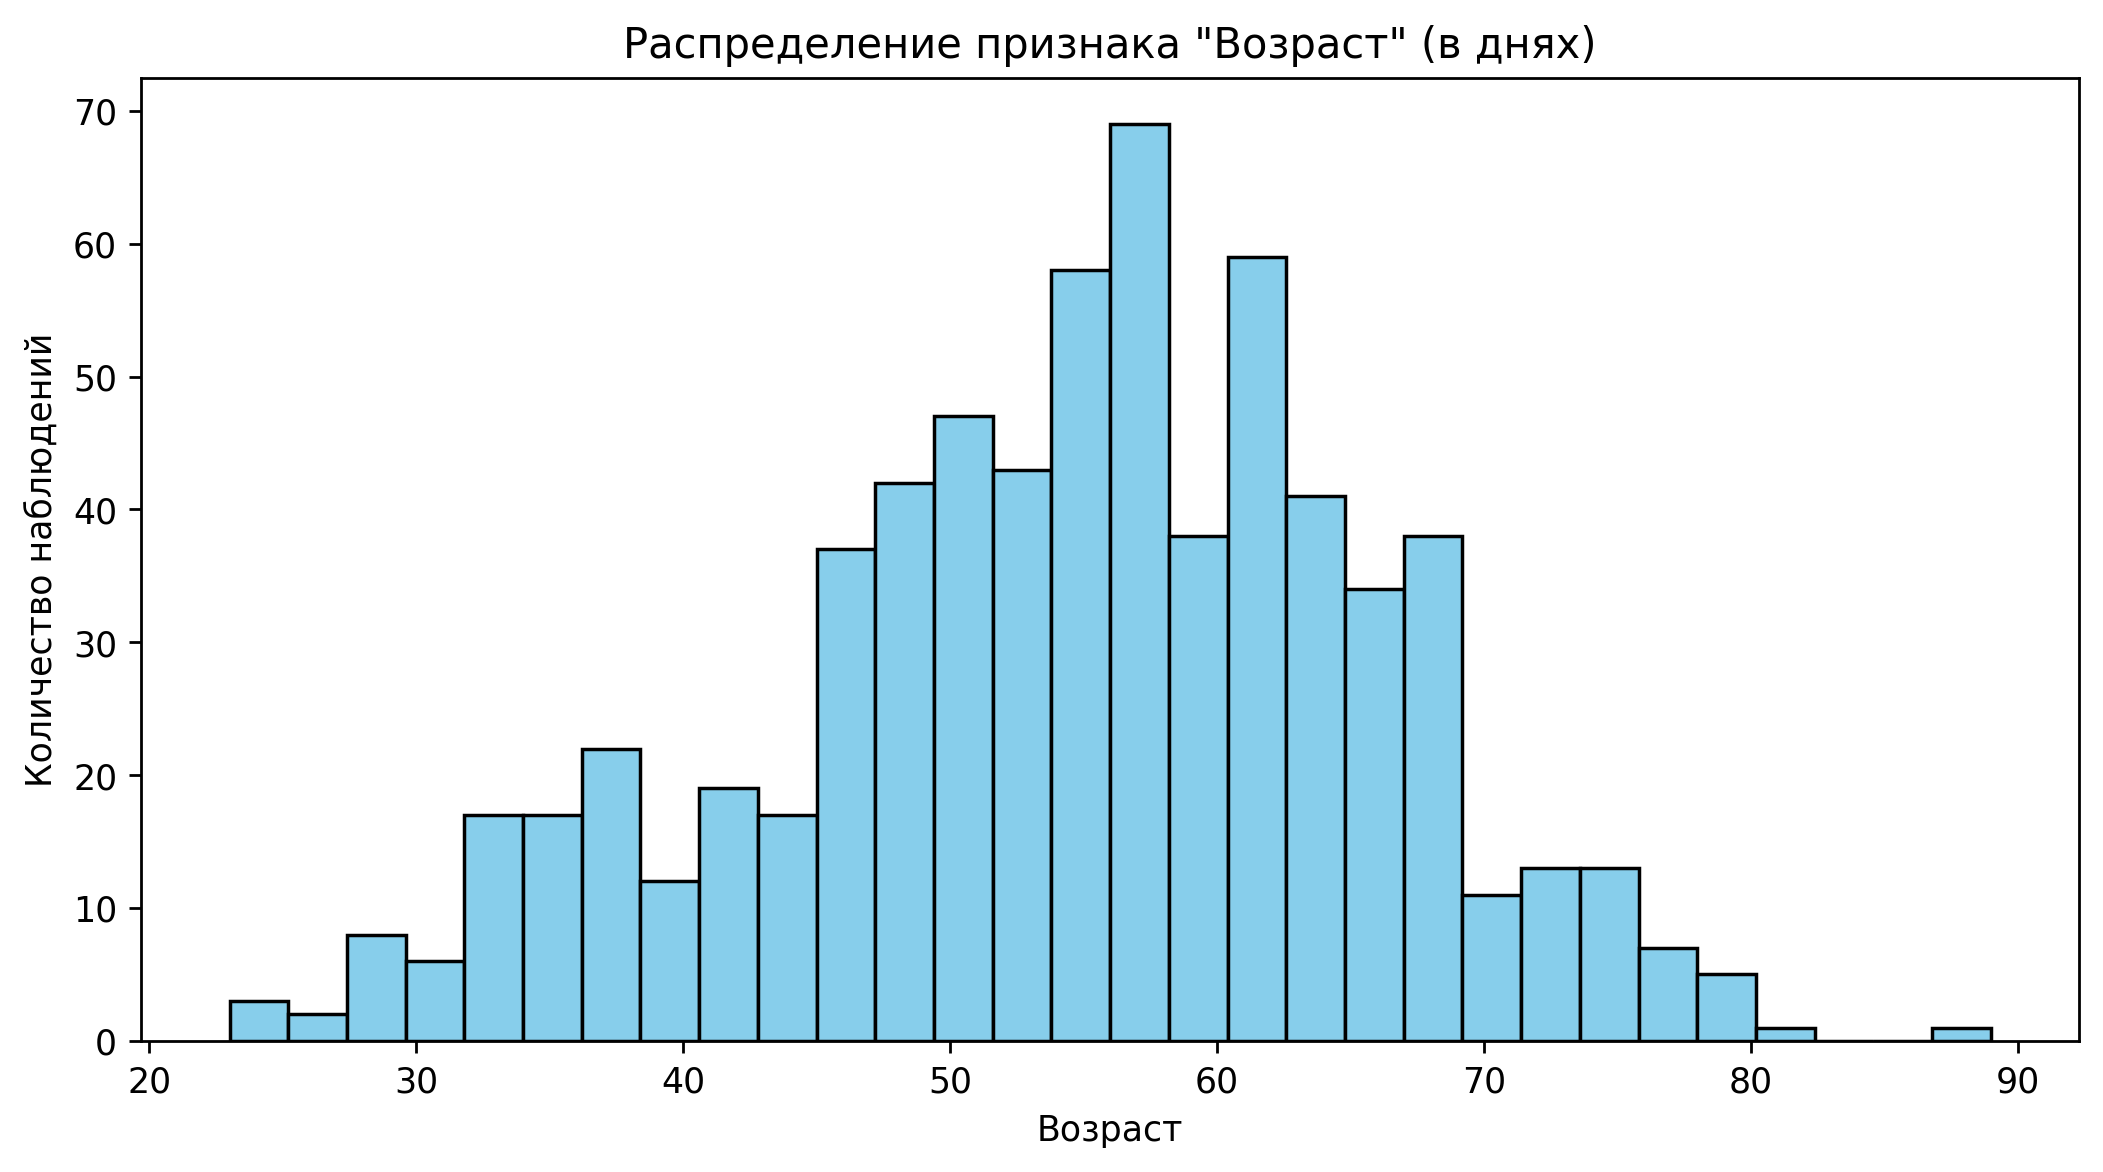

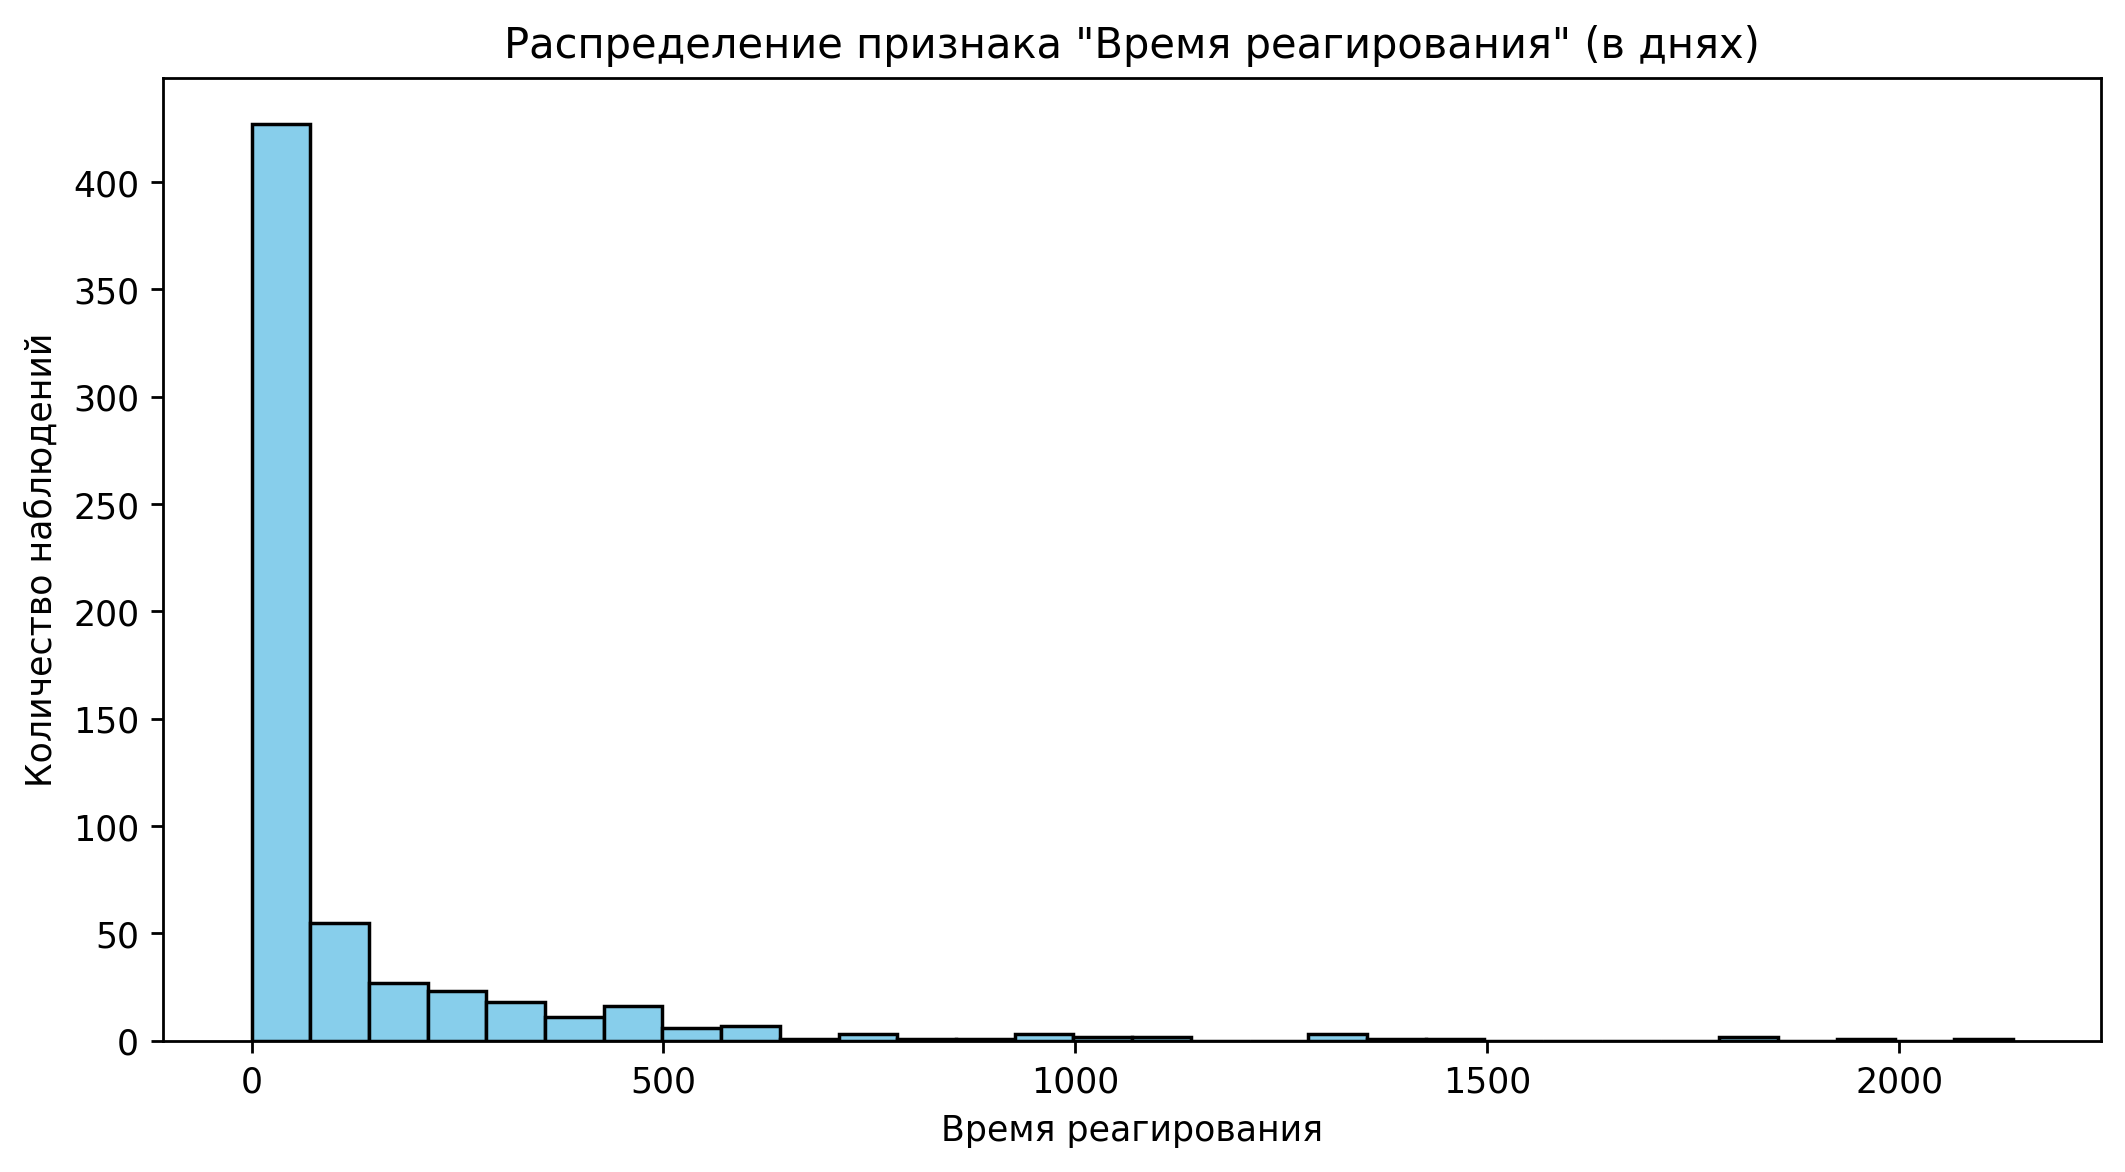

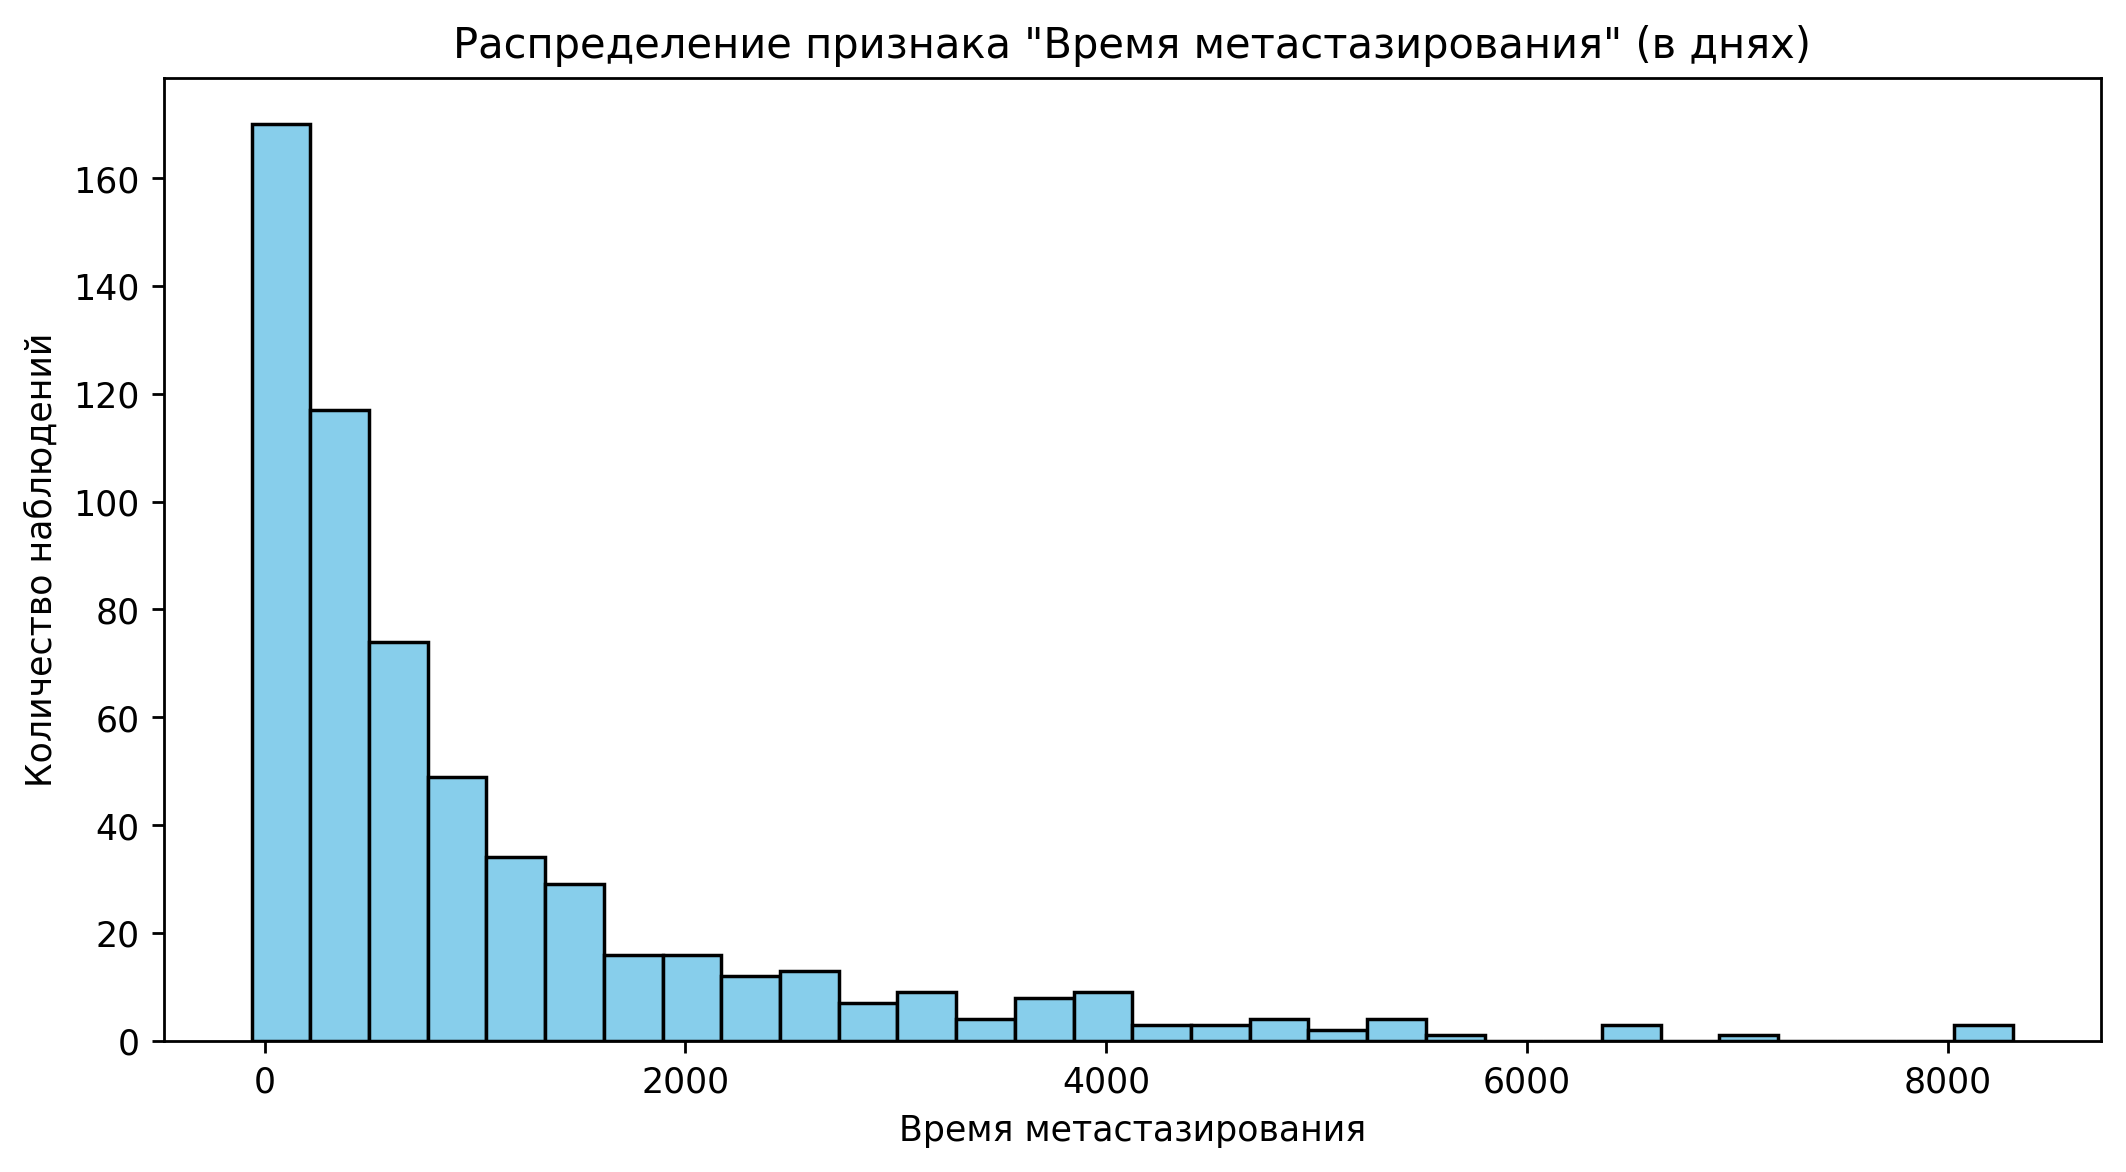

In [64]:
# рассмотриваем распределения новых признаков (созданных из дат)
# строим гистограмму:
for feature in ["Время от удаления первичного очага до 1-ой РХ",
                "Время от ОВГМ до 1-ой РХ", "Время от операции на ГМ до 1-ой РХ",
                "Возраст", "Время реагирования", "Время метастазирования"]:
  plt.figure(figsize=(10,5), dpi=250)
  plt.hist(df[feature], bins=30, color='skyblue', edgecolor='black')
  plt.title(f'Распределение признака "{feature}" (в днях)')
  plt.xlabel(feature)
  plt.ylabel('Количество наблюдений')
  plt.grid(False)
  plt.show()

In [65]:
# заметив сильный перекос данных вправо на последних двух графиках, вручную проверяем выбросы
# и методом пристального взгляда находим индексы с подозрительными данными
suspicious_idx_reaction = [573, 759, 1, 5, 414, 155, 275, 540, 811]

suspicious_idx_metastasis = [272, 702, 582, 475, 196, 420, 770, 1, 462, 410, 43, 803, 834, 275, 177, 307]

In [66]:
# исправляем временные аномалии аналогично кейсу с отрицательным временем
def fix_time_anomalies(idxes, col_name):
  df.loc[idxes, col_name] = 0
  df.loc[idxes, 'Временные аномалии'] = 1

fix_time_anomalies(suspicious_idx_reaction, 'Время метастазирования')
fix_time_anomalies(suspicious_idx_metastasis, 'Время метастазирования')

In [67]:
# заменяем все пропущенные значения на медиану обучающей выборки
for feature in ["Возраст", "Время реагирования", "Время метастазирования"]:
  df.loc[df[feature].isna(), feature] = df[feature].median()

In [68]:
# Заполнение пропусков в test_df медианами из тренировочного df
for feature in ["Возраст", "Время реагирования", "Время метастазирования"]:
  test_df.loc[test_df[feature].isna(), feature] = df[feature].median()

## Удаление неинтерпретируемых признаков дат

In [69]:
# df = df.drop("Дата рождения", axis=1)
# df = df.drop("Дата развития МГМ", axis=1)
# df = df.drop("Дата постановки онкологического диагноза / начала первичного лечения", axis=1)
# df = df.drop("Дата 1-ой РХ", axis=1)
# df = df.drop("Дата удаления первичного очага", axis=1)
# df = df.drop("Дата проведения ОВГМ", axis=1)
# df = df.drop("Дата операции на ГМ", axis=1)

# - можно разкомментить если хочется посмотреть df, но удалять не обязательно,
# кэтбуст сам не будет воспринимать такие признаки если они ему не нужны
# НО! в катбусте обязательно поставить has_time=True

## Предотвращение утечки данных

In [70]:
# исключим все признаки, появившиеся после результата рецидив/не рецидив
df = df.drop("Локальный рецидив", axis=1)
df = df.drop("Дистантные метастазы", axis=1)

## Корреляционный анализ

In [71]:
# исходя из матрицы корреляции, увидим, что
# 1) "Объем максимального очага"" и "Объём очагов" коррелируют очень сильно
# 2) "Объем максимального очага"" и "Средний объём очага" коррелируют весомо
# исходя из этого было принято решение об удалении признака "Объем максимального очага""
df = df.drop("Объем максимального очага", axis=1)

## Обработка пропусков категориальных переменных

In [72]:
df.dtypes

,0
Дата рождения,datetime64[ns]
Онкологический диагноз,object
Дата постановки онкологического диагноза / начала первичного лечения,datetime64[ns]
Дата удаления первичного очага,datetime64[ns]
Дата развития МГМ,datetime64[ns]
Активирующие мутации,float64
Дата проведения ОВГМ,datetime64[ns]
Дата операции на ГМ,datetime64[ns]
Число РХ процедур на ГН,int64
Дата 1-ой РХ,datetime64[ns]


In [73]:
for feature in df.select_dtypes(include="object").columns:
  df[feature] = df[feature].fillna("неизвестно")

In [74]:
# Категориальные пропуски для test_df
for feature in test_df.select_dtypes(include="object").columns:
  test_df[feature] = test_df[feature].fillna("неизвестно")

In [75]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 680 entries, 0 to 870
Data columns (total 27 columns):
 #   Column                                                                Non-Null Count  Dtype         
---  ------                                                                --------------  -----         
 0   Дата рождения                                                         680 non-null    datetime64[ns]
 1   Онкологический диагноз                                                680 non-null    object        
 2   Дата постановки онкологического диагноза / начала первичного лечения  619 non-null    datetime64[ns]
 3   Дата удаления первичного очага                                        352 non-null    datetime64[ns]
 4   Дата развития МГМ                                                     612 non-null    datetime64[ns]
 5   Активирующие мутации                                                  270 non-null    float64       
 6   Дата проведения ОВГМ                           

## Итоговый датасет:

In [76]:
df

,Дата рождения,Онкологический диагноз,Дата постановки онкологического диагноза / начала первичного лечения,Дата удаления первичного очага,Дата развития МГМ,Активирующие мутации,Дата проведения ОВГМ,Дата операции на ГМ,Число РХ процедур на ГН,Дата 1-ой РХ,...,Время метастазирования,Временные аномалии,Первичный очаг до 1-ой РХ,Время от удаления первичного очага до 1-ой РХ,ОВГМ до 1-ой РХ,Время от ОВГМ до 1-ой РХ,Операция на ГМ до 1-ой РХ,Время от операции на ГМ до 1-ой РХ,Ожидаемая прогрессия,Пол-Мужской
0,1947-06-04,НМРЛ,2008-04-01,NaT,2009-05-01,NaN,NaT,NaT,1,2009-11-10,...,395.0,0,False,NaN,False,NaN,False,NaN,нет,0
1,1951-03-13,РП,1992-12-01,NaT,2008-05-01,NaN,NaT,2008-05-01,3,2013-03-21,...,0.0,1,False,NaN,False,NaN,True,1785.0,ЛР+ДМ,0
2,1957-06-21,Меланома,2008-02-01,2008-02-01,2009-06-01,NaN,NaT,NaT,1,2009-10-08,...,486.0,0,True,615.0,False,NaN,False,NaN,ДМ,0
3,1959-02-24,НМРЛ,2013-12-01,NaT,2014-05-30,NaN,NaT,NaT,1,2014-07-14,...,180.0,0,False,NaN,False,NaN,False,NaN,нет,0
4,1961-12-19,КРР,2010-12-29,2010-12-29,2013-09-01,NaN,NaT,2013-09-01,1,2015-02-26,...,977.0,0,True,1520.0,False,NaN,True,543.0,нет,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
866,1977-07-31,Меланома,2011-05-13,2011-05-13,2013-06-17,1.0,2017-02-06,NaT,3,2013-06-17,...,766.0,0,True,766.0,False,-1330.0,False,NaN,ЛР+ДМ,1
867,1980-07-31,Меланома,2010-01-01,2010-01-01,2010-03-01,NaN,NaT,NaT,1,2010-04-01,...,59.0,0,True,90.0,False,NaN,False,NaN,нет,0
868,1945-08-31,НМРЛ,NaT,NaT,NaT,1.0,2012-04-18,NaT,1,2012-04-10,...,466.0,0,False,NaN,False,-8.0,False,NaN,нет,1
869,1953-08-31,РП,2007-07-01,2007-07-01,2008-12-01,NaN,NaT,NaT,1,2009-01-11,...,519.0,0,True,560.0,False,NaN,False,NaN,нет,1


In [77]:
!pip install catboost

In [78]:
from catboost import CatBoostClassifier, Pool
from sklearn.model_selection import train_test_split
from sklearn.metrics import balanced_accuracy_score

# 1. Создаем бинарную целевую переменную (1 - есть любая прогрессия, 0 - нет)
df['Прогрессия'] = (df['Ожидаемая прогрессия'] != 'нет').astype(int)

# 2. Изолируем признаки от неинтерпретируемых дат и старого таргета
cols_to_drop = df.select_dtypes(include=['datetime64[ns]']).columns.tolist() + ['Ожидаемая прогрессия']
X = df.drop(columns=cols_to_drop + ['Прогрессия'])
y = df['Прогрессия']

# 3. Определяем категориальные фичи для CatBoost (object и bool)
cat_features = X.select_dtypes(include=['object', 'bool']).columns.tolist()

# Убедимся, что категориальные признаки представлены строками (CatBoost это требует)
X[cat_features] = X[cat_features].astype(str)

# 4. Разбиваем данные на обучающую и валидационную выборки со стратификацией
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y # Обязательно для сохранения баланса классов в трейне и валидации
)

In [79]:
!pip install Optuna

Bagging CatBoost


In [80]:
import optuna
from catboost import CatBoostClassifier, Pool
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import balanced_accuracy_score
import numpy as np

def objective(trial):
    # Диапазоны гиперпараметров для поиска
    param = {
        "iterations": 1000,
        "learning_rate": trial.suggest_float("learning_rate", 1e-3, 0.1, log=True),
        "depth": trial.suggest_int("depth", 4, 10),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1, 10),
        "bootstrap_type": trial.suggest_categorical("bootstrap_type", ["Bayesian", "Bernoulli"]),
        "random_strength": trial.suggest_float("random_strength", 1e-8, 10, log=True),
        "od_type": "Iter",
        "od_wait": 50,
        "verbose": False,
        "random_seed": 42,
        "auto_class_weights": "Balanced"
    }

    if param["bootstrap_type"] == "Bernoulli":
        param["subsample"] = trial.suggest_float("subsample", 0.4, 1.0)

    # Кросс-валидация для оценки параметров
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    cv_scores = []

    for train_idx, val_idx in cv.split(X, y):
        X_train_cv, X_val_cv = X.iloc[train_idx], X.iloc[val_idx]
        y_train_cv, y_val_cv = y.iloc[train_idx], y.iloc[val_idx]

        model = CatBoostClassifier(**param)
        model.fit(X_train_cv, y_train_cv, eval_set=(X_val_cv, y_val_cv), cat_features=cat_features)

        preds = model.predict(X_val_cv)
        score = balanced_accuracy_score(y_val_cv, preds)
        cv_scores.append(score)

    return np.mean(cv_scores)

# Запуск процесса поиска (рекомендую 50-100 итераций)
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=50)

print(f"Лучший результат: {study.best_value}")
print(f"Лучшие параметры: {study.best_params}")

[I 2026-05-24 14:22:19,614] A new study created in memory with name: no-name-89f6034d-3544-4035-b523-5573ee599f49
[W 2026-05-24 14:22:26,066] Trial 0 failed with parameters: {'learning_rate': 0.0033735709343829597, 'depth': 9, 'l2_leaf_reg': 4.535645178543264, 'bootstrap_type': 'Bayesian', 'random_strength': 6.429289981501586} because of the following error: KeyboardInterrupt('').
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/optuna/study/_optimize.py", line 206, in _run_trial
    value_or_values = func(trial)
                      ^^^^^^^^^^^
  File "/tmp/ipykernel_1039/1247070453.py", line 35, in objective
    model.fit(X_train_cv, y_train_cv, eval_set=(X_val_cv, y_val_cv), cat_features=cat_features)
  File "/usr/local/lib/python3.12/dist-packages/catboost/core.py", line 5547, in fit
    self._fit(X, y, cat_features, text_features, embedding_features, None, graph, sample_weight, None, None, None, None, baseline, use_best_model,
  File "/usr/local/

KeyboardInterrupt: 

In [81]:
# Прописываем лучшие параметры вручную
best_params = {
    'learning_rate': 0.07985748292995348,
    'depth': 4,
    'l2_leaf_reg': 4.173565289433228,
    'bootstrap_type': 'Bayesian',
    'random_strength': 4.372026144360919e-05,
    'eval_metric': 'AUC',
    'random_seed': 42
}

In [82]:
best_params.update({"iterations": 2000, "auto_class_weights": "Balanced", "verbose": 200})

models_ensemble = []
oof_preds = np.zeros(len(X))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for i, (train_idx, val_idx) in enumerate(cv.split(X, y)):
    print(f"Обучение модели на фолде {i+1}")
    X_train_fold, X_val_fold = X.iloc[train_idx], X.iloc[val_idx]
    y_train_fold, y_val_fold = y.iloc[train_idx], y.iloc[val_idx]

    model = CatBoostClassifier(**best_params)
    model.fit(X_train_fold, y_train_fold, eval_set=(X_val_fold, y_val_fold), cat_features=cat_features)

    models_ensemble.append(model)
    oof_preds[val_idx] = model.predict_proba(X_val_fold)[:, 1]

best_threshold = 0.5
best_score = 0
for thresh in np.arange(0.1, 0.9, 0.01):
    score = balanced_accuracy_score(y, (oof_preds > thresh).astype(int))
    if score > best_score:
        best_score = score
        best_threshold = thresh

print(f"Оптимальный порог: {best_threshold:.2f} с Balanced Accuracy: {best_score:.4f}")

Обучение модели на фолде 1
0:	test: 0.7029304	best: 0.7029304 (0)	total: 19ms	remaining: 38s
200:	test: 0.7250305	best: 0.7433455 (63)	total: 951ms	remaining: 8.51s
400:	test: 0.7294261	best: 0.7433455 (63)	total: 1.78s	remaining: 7.09s
600:	test: 0.7277167	best: 0.7433455 (63)	total: 3.04s	remaining: 7.06s
800:	test: 0.7272283	best: 0.7433455 (63)	total: 4.18s	remaining: 6.26s
1000:	test: 0.7216117	best: 0.7433455 (63)	total: 5.98s	remaining: 5.97s
1200:	test: 0.7206349	best: 0.7433455 (63)	total: 7.41s	remaining: 4.93s
1400:	test: 0.7240537	best: 0.7433455 (63)	total: 8.36s	remaining: 3.57s
1600:	test: 0.7177045	best: 0.7433455 (63)	total: 9.18s	remaining: 2.29s
1800:	test: 0.7196581	best: 0.7433455 (63)	total: 10.2s	remaining: 1.13s
1999:	test: 0.7194139	best: 0.7433455 (63)	total: 11.2s	remaining: 0us

bestTest = 0.7433455433
bestIteration = 63

Shrink model to first 64 iterations.
Обучение модели на фолде 2
0:	test: 0.7860806	best: 0.7860806 (0)	total: 18.1ms	remaining: 36.2s
200:

In [83]:
# 1. Убеждаемся, что колонки в тесте такие же, как в трейне


# 2. Собираем предсказания от всех моделей ансамбля
ensemble_test_probs = []

for model in models_ensemble:
    probs = model.predict_proba(X_test)[:, 1]
    ensemble_test_probs.append(probs)

final_test_probs = np.mean(ensemble_test_probs, axis=0)

final_test_preds = (final_test_probs > best_threshold).astype(int)

submission = pd.DataFrame({
    'ID': test_df['ID'] if 'ID' in test_df.columns else test_df.index,
    'Интракраниальная прогрессия': final_test_preds
})
submission.to_csv('privet.csv', index=False)
print("Файл успешно сохранен!")

Файл успешно сохранен!


In [84]:
final_test_preds

array([1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0,
       0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1])

### **Анализ метрик и важности признаков**

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    roc_curve
)

def evaluate_oof_ensemble_and_plot(X, y, models, cv_splitter, best_threshold=0.5):
    """
    Рассчитывает честные Out-of-Fold метрики для ансамбля из 5 моделей,
    выводит их таблицей и генерирует графики (Confusion Matrix и ROC-кривую) для статьи.

    Параметры:
    ----------
    X : pandas.DataFrame или np.array
        Матрица признаков (X_train)
    y : pandas.Series или np.array
        Истинные клинические исходы (0 или 1)
    models_dict : dict
        Словарь с вашими 5 обученными моделями CatBoost
    cv_splitter : KFold или StratifiedKFold
        Объект кросс-валидации, использовавшийся при обучении
    best_threshold : float, default=0.5
        Порог отсечения вероятностей для предсказания рецидива
    file_prefix : str
        Префикс для сохранения названий файлов картинок
    """
    # 1. Сбор Out-of-Fold предсказаний
    oof_probs = np.zeros(len(X))
    X_df = pd.DataFrame(X) if isinstance(X, np.ndarray) else X
    y_arr = np.array(y)

    for fold, (train_idx, val_idx) in enumerate(cv_splitter.split(X_df, y_arr)):
        model = models[fold]
        # Предсказываем вероятность для валидационного фолда текущей модели
        oof_probs[val_idx] = model.predict_proba(X_df.iloc[val_idx])[:, 1]

    # Применяем порог для бинарной классификации
    oof_preds = (oof_probs > best_threshold).astype(int)

    # 2. Расчет метрик
    sensitivity = recall_score(y_arr, oof_preds)
    balanced_acc = balanced_accuracy_score(y_arr, oof_preds)
    specificity = (balanced_acc * 2) - sensitivity

    metrics = {
        "Accuracy (Общая точность)": accuracy_score(y_arr, oof_preds),
        "Balanced Accuracy (Сбалансированная)": balanced_acc,
        "Sensitivity / Recall (Чувствительность)": sensitivity,
        "Specificity (Специфичность)": specificity,
        "Precision (Точность прогноза)": precision_score(y_arr, oof_preds),
        "F1-Score (F-мера)": f1_score(y_arr, oof_preds),
        "ROC-AUC (Площадь под кривой)": roc_auc_score(y_arr, oof_probs)
    }

    # Вывод результатов текстом
    print(f"\n{'Метрика (Ансамбль 5x CatBoost OOF)':<50} | {'Значение':<10}")
    print("-" * 65)
    for metric_name, value in metrics.items():
        print(f"{metric_name:<50} | {value:.4f}")
    print("-" * 65)

    # Настройки стиля для научных журналов (строгий белый стиль, крупные шрифты)
    sns.set_theme(style="white")
    plt.rcParams.update({'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 13})

    # 3. Отрисовка и сохранение Confusion Matrix
    cm = confusion_matrix(y_arr, oof_preds)
    plt.figure(figsize=(5.5, 4.5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Нет рецидива', 'Рецидив'],
                yticklabels=['Нет рецидива', 'Рецидив'])
    plt.title('Матрица ошибок ансамбля (OOF)', pad=15)
    plt.ylabel('Истинные клинические исходы')
    plt.xlabel('Предсказания ансамбля моделей')
    plt.tight_layout()
    plt.show()

    # 4. Отрисовка и сохранение ROC-кривой
    fpr, tpr, _ = roc_curve(y_arr, oof_probs)
    plt.figure(figsize=(5.5, 4.5))
    plt.plot(fpr, tpr, color='darkorange', lw=2,
             label=f'ROC-кривая ансамбля (AUC = {metrics["ROC-AUC (Площадь под кривой)"]:.3f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Кривая операционных характеристик (ROC OOF)', pad=15)
    plt.legend(loc="lower right")
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.show()

    return metrics, oof_probs

_ = evaluate_oof_ensemble_and_plot(X, y, models_ensemble, cv, best_threshold)

In [ ]:
import shap

# 1. Сбор и усреднение SHAP-значений по 5 моделям (тот же шаг)
all_shap_values = []
all_expected_values = []

for model in models_ensemble:
    explainer = shap.TreeExplainer(model)
    shap_values_single = explainer(X_ens)
    all_shap_values.append(shap_values_single.values)
    all_expected_values.append(shap_values_single.base_values)

mean_shap_values = np.mean(all_shap_values, axis=0)
mean_expected_value = np.mean(all_expected_values, axis=0)

ensemble_shap_values = shap.Explanation(
    values=mean_shap_values,
    base_values=mean_expected_value,
    data=X_ens.values,
    feature_names=X_ens.columns
)

# График 1: Полный Bar Plot
# Увеличиваем высоту графика (например, 12-14 дюймов), чтобы все строки поместились
plt.figure(figsize=(10, int(X_ens.shape[1] * 0.4) + 2))
shap.plots.bar(ensemble_shap_values, max_display=X_ens.shape[1], show=False)
plt.title("Полный профиль глобальной важности признаков ансамбля", pad=20)
plt.tight_layout()
plt.show()

# График 2: Полный Beeswarm Plot
plt.figure(figsize=(11, int(X_ens.shape[1] * 0.4) + 2))
shap.plots.beeswarm(ensemble_shap_values, max_display=X_ens.shape[1], show=False)
plt.title("Полное распределение влияния всех признаков на прогноз", pad=20)
plt.tight_layout()
plt.show()